# 03 — EDA, Stasioneritas, Waktu Informasi (Lead–Lag), dan Kualitas Data

Notebook ini hanya membaca `data/processed/data_gabungan.csv`; tidak bergantung pada hasil model.

Isi:
1. statistik deskriptif; 2. uji ADF; 3. level vs transformasi stasioner untuk 7 indikator makro;
4. distribusi return; 5. korelasi; **6. analisis waktu informasi (lead–lag)**; **7. porsi hari dengan return nol (harga basi)**.

Bagian 6 dan 7 menjawab dua pertanyaan yang pasti ditanyakan penguji/reviewer:
*"Apakah indikator makro yang dipakai benar-benar bisa memprediksi?"* dan *"Seberapa bersih data harga Antam?"*

In [10]:
import sys, os, json, time, warnings
sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK)
from src import analysis as A, plots as P, stats as S
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, RUNS, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    """Simpan figur (PNG + PDF) ke outputs/figures lalu tampilkan."""
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

from scipy.stats import norm
from statsmodels.tsa.stattools import adfuller
warnings.filterwarnings('ignore', category=FutureWarning)
from src.pipeline import EXO_COLS, EXO_LOGRET_COLS, EXO_DIFF_COLS, EXO_CLIP, multihorizon_split

r = df['emas_ret']
df.head()

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44


,harga_jual,emas_ret,bi_rate,dxy,sp500,usd_idr,ihsg,us10yr,ffr,dxy_ret,sp500_ret,usd_idr_ret,ihsg_ret,us10yr_diff,ffr_diff,bi_rate_diff
tanggal,,,,,,,,,,,,,,,,
2010-01-05,410000.0,0.490196,6.5,77.529999,1132.989990,9364.200195,2575.312988,3.85,0.12,0.000000,0.000000,0.000000,0.000000,0.00,0.0,0.0
2010-01-06,410000.0,0.000000,6.5,77.620003,1136.520020,9305.200195,2605.175537,3.77,0.12,0.001160,0.003111,-0.006321,0.011529,-0.08,0.0,0.0
2010-01-07,412000.0,0.487805,6.5,77.489998,1137.140015,9218.099609,2603.195557,3.85,0.12,-0.001676,0.000545,-0.009405,-0.000760,0.08,0.0,0.0
2010-01-08,410000.0,-0.485437,6.5,77.910004,1141.689941,9272.500000,2586.794189,3.85,0.12,0.005405,0.003993,0.005884,-0.006320,0.00,0.0,0.0
2010-01-11,413000.0,0.731707,6.5,77.470001,1144.979980,9212.700195,2614.268311,3.83,0.12,-0.005664,0.002878,-0.006470,0.010565,-0.02,0.0,0.0


## 1. Statistik Deskriptif

In [11]:
desc = df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc.to_csv(os.path.join(RES, 'statistik_deskriptif.csv'))
desc.round(3)

,count,mean,std,min,25%,50%,75%,max
harga_jual,4325.0,886115.260,534841.960,394000.000,568000.000,657000.000,988000.000,3168000.000
emas_ret,4325.0,0.046,0.754,-6.046,-0.333,0.000,0.399,5.495
bi_rate,4325.0,5.646,1.204,3.500,4.750,5.750,6.500,7.750
dxy,4325.0,92.971,9.281,72.930,82.750,95.520,99.380,114.110
sp500,4325.0,3093.306,1655.368,1022.580,1844.860,2664.110,4188.430,7609.780
usd_idr,4325.0,13213.850,2498.663,8292.700,11590.000,13865.000,14895.000,18190.301
ihsg,4325.0,5586.806,1326.577,2475.476,4578.000,5754.965,6647.065,9134.700
us10yr,4325.0,2.673,1.036,0.520,1.890,2.520,3.510,4.980
ffr,4325.0,1.477,1.821,0.050,0.100,0.360,2.400,5.330
dxy_ret,4325.0,0.000,0.004,-0.024,-0.002,0.000,0.002,0.020


## 2. Uji Stasioneritas (Augmented Dickey–Fuller)

H0: deret memiliki unit root (non-stasioner). Harga level, return, dan selisih pertama harga dibandingkan, untuk menegaskan mengapa target model dibangun dari **return kumulatif h-hari**, bukan harga level.

In [12]:
adf_rows = []
for nama, series in [('harga_jual (level)', p), ('emas_ret (return)', r), ('harga_jual (diff-1)', p.diff().dropna())]:
    res = adfuller(series.dropna(), autolag='AIC')
    adf_rows.append({'variabel': nama, 'ADF_stat': round(res[0], 4), 'p_value': round(res[1], 4),
                     'kritis_1pct': round(res[4]['1%'], 4), 'kritis_5pct': round(res[4]['5%'], 4),
                     'lag': res[2], 'obs': res[3], 'stasioner': res[1] < 0.05})
adf_df = pd.DataFrame(adf_rows)
adf_df.to_csv(os.path.join(RES, 'adf_hasil.csv'), index=False)
adf_df

,variabel,ADF_stat,p_value,kritis_1pct,kritis_5pct,lag,obs,stasioner
0,harga_jual (level),1.4424,0.9973,-3.4319,-2.8622,31,4293,False
1,emas_ret (return),-22.7899,0.0000,-3.4319,-2.8622,7,4317,True
2,harga_jual (diff-1),-8.2807,0.0000,-3.4319,-2.8622,30,4293,True


## 3. Eksogen: Level vs Transformasi Stasioner

Untuk tiap indikator dibandingkan **level** dan **fitur stasioner** (log-return untuk indeks/kurs, selisih untuk suku bunga/yield):

- **ADF p-value** — level hampir pasti non-stasioner; transformasi harus stasioner.
- **% hari uji di luar rentang train** — bila tinggi, model berbasis level terpaksa *mengekstrapolasi*.
- **max |z| di uji** — z-score memakai rata-rata/simpangan baku **train saja** (sama dengan pipeline model), dihitung *sebelum* clipping `EXO_CLIP`.

Split yang dipakai: h=20 (representatif; batas split antar-horizon hampir sama).

In [13]:
PASANGAN = ([(c, f'{c}_ret') for c in EXO_LOGRET_COLS] + [(c, f'{c}_diff') for c in EXO_DIFF_COLS])
tr_d, va_d, te_pos = multihorizon_split(p, 20)
te_d = p.index[te_pos]


def adf_p(s):
    return adfuller(s.dropna(), autolag='AIC')[1]


def luar_rentang(s):
    lo, hi = s.loc[tr_d].min(), s.loc[tr_d].max()
    return float(((s.loc[te_d] < lo) | (s.loc[te_d] > hi)).mean() * 100)


def max_abs_z(s):
    mu, sd = s.loc[tr_d].mean(), s.loc[tr_d].std()
    return float(((s.loc[te_d] - mu) / sd).abs().max())


rows = []
for lvl, fit in PASANGAN:
    rows.append({'indikator': lvl,
                 'ADF_p_level': round(adf_p(df[lvl]), 4), 'ADF_p_stasioner': round(adf_p(df[fit]), 4),
                 'uji_luar_rentang_train_%_level': round(luar_rentang(df[lvl]), 1),
                 'uji_luar_rentang_train_%_stasioner': round(luar_rentang(df[fit]), 1),
                 'max_abs_z_uji_level': round(max_abs_z(df[lvl]), 1),
                 'max_abs_z_uji_stasioner': round(max_abs_z(df[fit]), 1)})
eks = pd.DataFrame(rows)
eks.to_csv(os.path.join(RES, 'eksogen_level_vs_stasioner.csv'), index=False)
print(f'Clip z-score input DL untuk kanal eksogen: ±{EXO_CLIP}')
eks

Clip z-score input DL untuk kanal eksogen: ±5.0


,indikator,ADF_p_level,ADF_p_stasioner,uji_luar_rentang_train_%_level,uji_luar_rentang_train_%_stasioner,max_abs_z_uji_level,max_abs_z_uji_stasioner
0,dxy,0.3644,0.0,41.2,0.0,2.6,4.6
1,sp500,0.9983,0.0,87.3,0.1,6.9,8.4
2,usd_idr,0.8992,0.0,28.2,0.0,2.8,4.3
3,ihsg,0.1924,0.0,87.2,0.0,4.2,7.7
4,us10yr,0.6998,0.0,79.3,0.0,3.9,4.0
5,ffr,0.7183,0.0,100.0,0.0,6.5,12.5
6,bi_rate,0.4388,0.0,0.0,0.0,0.9,12.8


## 4. Distribusi Return dan Harga

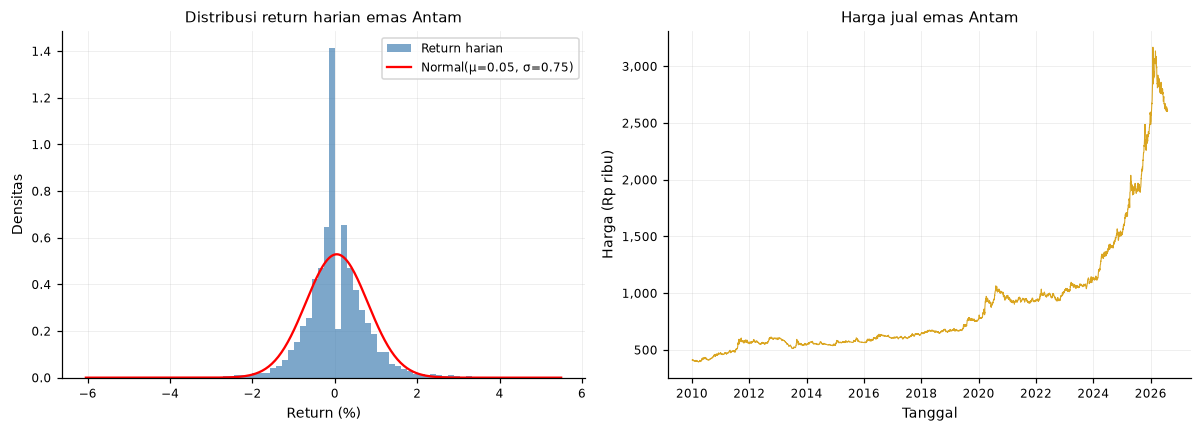

Kurtosis berlebih return harian: 6.1  (normal = 0; >0 = ekor tebal)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
mu, sigma = r.mean(), r.std()
ax.hist(r, bins=80, density=True, color='steelblue', alpha=0.7, label='Return harian')
x = np.linspace(r.min(), r.max(), 300)
ax.plot(x, norm.pdf(x, mu, sigma), 'r-', lw=1.5, label=f'Normal(μ={mu:.2f}, σ={sigma:.2f})')
ax.set_title('Distribusi return harian emas Antam')
ax.set_xlabel('Return (%)'); ax.set_ylabel('Densitas'); ax.legend(fontsize=8)
ax2 = axes[1]
ax2.plot(p.index, p.values / 1000, lw=0.7, color='goldenrod')
ax2.set_title('Harga jual emas Antam')
ax2.set_xlabel('Tanggal'); ax2.set_ylabel('Harga (Rp ribu)')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
fig.tight_layout()
simpan(fig, 'eda_distribusi_return')
print(f'Kurtosis berlebih return harian: {r.kurt():.1f}  (normal = 0; >0 = ekor tebal)')

## 5. Korelasi Return Emas dengan Fitur Eksogen

> **Perhatian membaca angka ini.** Kolom eksogen di `data_gabungan.csv` sudah di-*lag* 1 hari: baris *t* memuat nilai pasar hari *t−1*.
> Harga Antam hari *t* diumumkan pagi hari WIB, setelah pasar AS hari *t−1* tutup. Jadi korelasi `emas_ret(t)` dengan fitur ber-lag-1 di bawah ini
> **bersifat kontemporer** (harga Antam hari *t* sudah memuat informasi itu), **bukan** daya prediksi untuk hari *t+1* ke depan.
> Bagian 6 memisahkan keduanya secara eksplisit. (Versi sebelumnya menyebut korelasi ini "prediktif sungguhan" — itu keliru dan sudah dikoreksi.)

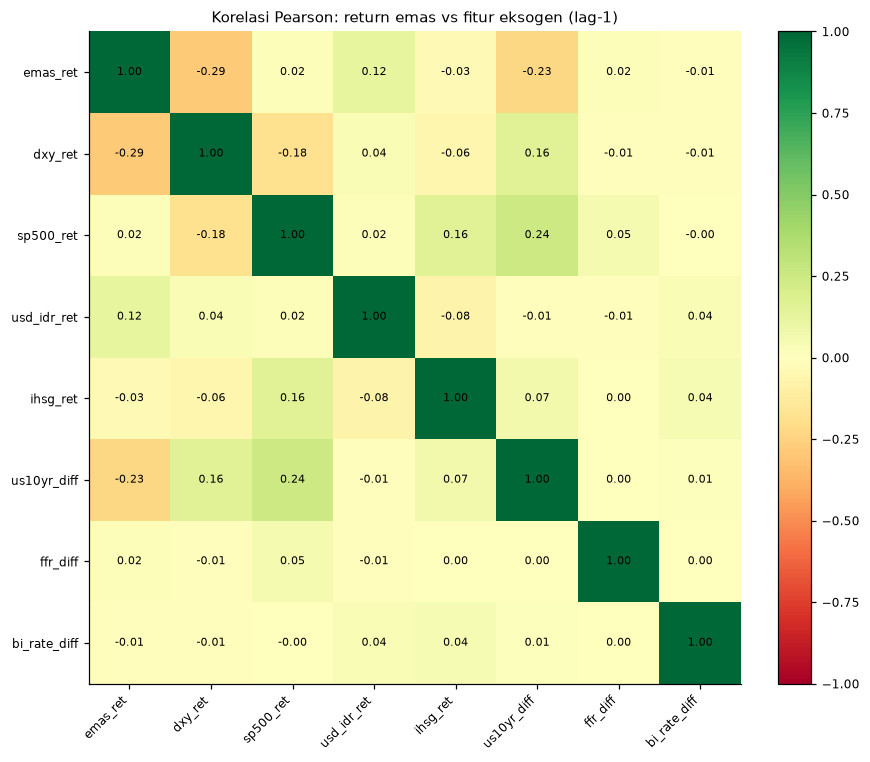

In [15]:
kolom_korelasi = ['emas_ret'] + EXO_COLS
corr = df[kolom_korelasi].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1)
labels = corr.columns.tolist()
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=7, color='black')
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title('Korelasi Pearson: return emas vs fitur eksogen (lag-1)')
fig.tight_layout()
simpan(fig, 'eda_korelasi_variabel')

## 6. Waktu Informasi: Kapan Berita Makro Masuk ke Harga Antam?

Pertanyaan: apakah fitur makro ber-lag-1 yang dipakai model (nilai hari *t−1* di origin *t*) masih membawa informasi **baru** tentang return Antam berikutnya?

- **(a)** korelasi `return Antam(t)` dengan nilai makro hari *t−2*, *t−1* (yang dipakai model), dan *t* (hari yang sama);
- **(b)** korelasi dengan `return Antam(t+1)` — ini yang relevan untuk peramalan: fitur yang **dipakai** (nilai *t−1* di origin *t*) vs nilai **penutupan hari *t*** (tersedia malam hari *t*, sebelum harga Antam *t+1* diumumkan; dipakai pada **skenario B**, notebook 15).

Dengan n ≈ 4.300 hari, korelasi di bawah ±0,03 tidak dapat dibedakan dari nol (±1,96/√n).

Pita ±1,96/√n = ±0.030


,dxy_ret,sp500_ret,usd_idr_ret,ihsg_ret,us10yr_diff,ffr_diff,bi_rate_diff
X(t−2),0.094,-0.074,0.032,-0.084,-0.022,-0.037,-0.049
X(t−1),-0.288,0.021,0.118,-0.033,-0.233,0.021,-0.012
X(t),-0.062,-0.009,-0.050,0.035,-0.017,0.016,-0.005


,dxy_ret,sp500_ret,usd_idr_ret,ihsg_ret,us10yr_diff,ffr_diff,bi_rate_diff
used,0.094,-0.074,0.032,-0.084,-0.022,-0.037,-0.049
sameday,-0.288,0.021,0.118,-0.033,-0.233,0.021,-0.012


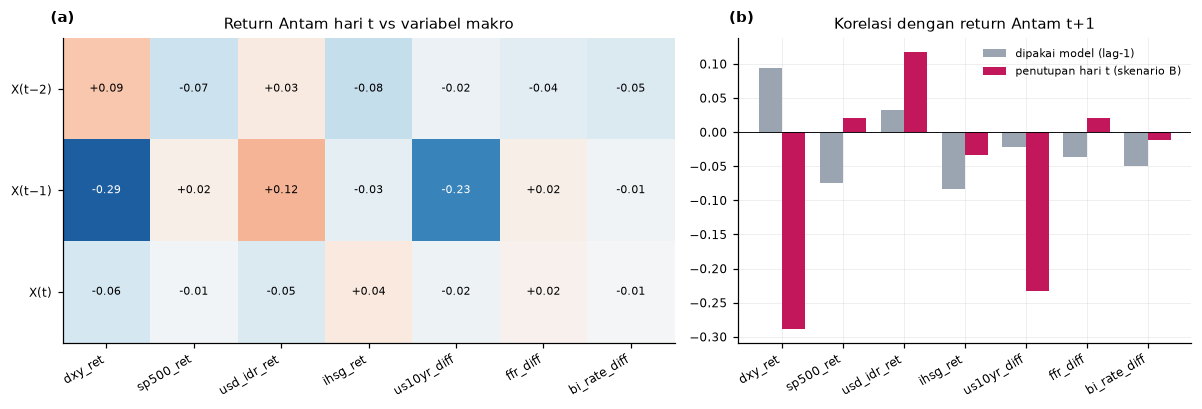

In [16]:
A_ret = np.log(p).diff()                       # log-return Antam hari t
VARS = EXO_COLS


def korelasi(y, x):
    m = y.notna() & x.notna()
    return float(np.corrcoef(y[m], x[m])[0, 1])


# data_gabungan[c][t] = X(t-1)  ->  X(t-L) = df[c].shift(L-1)
BARIS = {'X(t−2)': 2, 'X(t−1)': 1, 'X(t)': 0}
cc_contemp = pd.DataFrame({c: [korelasi(A_ret, df[c].shift(L - 1)) for L in BARIS.values()] for c in VARS}, index=list(BARIS))
cc_pred = pd.DataFrame({c: [korelasi(A_ret.shift(-1), df[c]), korelasi(A_ret.shift(-1), df[c].shift(-1))] for c in VARS},
                       index=['used', 'sameday'])
pita = 1.96 / np.sqrt(A_ret.notna().sum())
print(f'Pita ±1,96/√n = ±{pita:.3f}')
display(cc_contemp.round(3))
display(cc_pred.round(3))
pd.concat({'korelasi_dengan_return_t': cc_contemp, 'korelasi_dengan_return_t+1': cc_pred}).to_csv(os.path.join(RES, 'leadlag_waktu_informasi.csv'))

fig = P.fig_leadlag(cc_contemp, cc_pred)
simpan(fig, 'fig_leadlag')

In [17]:
# Seberapa besar informasi yang hilang karena lag-1? R^2 in-sample regresi linear return(t+1) ~ 7 fitur makro.
def r2_insample(y, X):
    m = y.notna() & X.notna().all(axis=1)
    Xm = np.column_stack([np.ones(m.sum()), X[m].values])
    b = np.linalg.lstsq(Xm, y[m].values, rcond=None)[0]
    e = y[m].values - Xm @ b
    return float(1 - e.var() / y[m].values.var())


Y = A_ret.shift(-1)
r2_dipakai = r2_insample(Y, df[VARS])                    # nilai t-1 (yang dipakai model)
r2_hariini = r2_insample(Y, df[VARS].shift(-1))          # nilai penutupan t
print(f'R² in-sample (hanya indikasi, bukan evaluasi): fitur lag-1 = {r2_dipakai:.3f} | penutupan hari-t = {r2_hariini:.3f}')

R² in-sample (hanya indikasi, bukan evaluasi): fitur lag-1 = 0.021 | penutupan hari-t = 0.137


**Interpretasi (jujur).**

1. Korelasi terkuat dengan `return Antam(t)` muncul pada nilai makro hari *t−1* (panel a, baris tengah: DXY ≈ −0,29, US10Y ≈ −0,23, USD/IDR ≈ +0,12) karena harga Antam hari *t* sudah memuat penutupan pasar global hari *t−1*.
   Itu informasi yang **sudah ada** di harga, bukan daya prediksi ke depan.
2. Untuk memprediksi return *t+1*, fitur yang **dipakai** model (nilai *t−1* di origin *t*; batang abu-abu) hanya berkorelasi lemah (|ρ| ≤ ≈0,09), sedangkan nilai **penutupan hari *t*** (batang merah; tersedia malam hari *t*, sebelum harga Antam *t+1* diumumkan) berkorelasi jauh lebih kuat (DXY ≈ −0,29, US10Y ≈ −0,23). R² in-sample regresi linear: ≈ 2% (lag-1) vs ≈ 14% (hari-t). Karena itu notebook 15 menjalankan **skenario B** sebagai analisis sensitivitas.
3. Desain lag-1 pada eksperimen utama **bukan kebocoran** (justru konservatif); hanya saja ia membuat kesimpulan "makro tidak membantu" sebagian bersifat konsekuensi desain. Hal ini harus dituliskan di bagian keterbatasan dan dibandingkan dengan hasil skenario B.

## 7. Porsi Hari dengan Return Nol (Harga Basi)

Dataset Antam bukan deret resmi per hari: pada hari tanpa pengumuman harga sebelumnya dipertahankan (*forward-fill*). Porsi `return = 0` yang tinggi di tahun-tahun awal menandakan banyak harga basi, yang mengubah karakter data antar-periode.

,latih,validasi,uji
porsi_return_nol_%,22.5,12.8,7.2


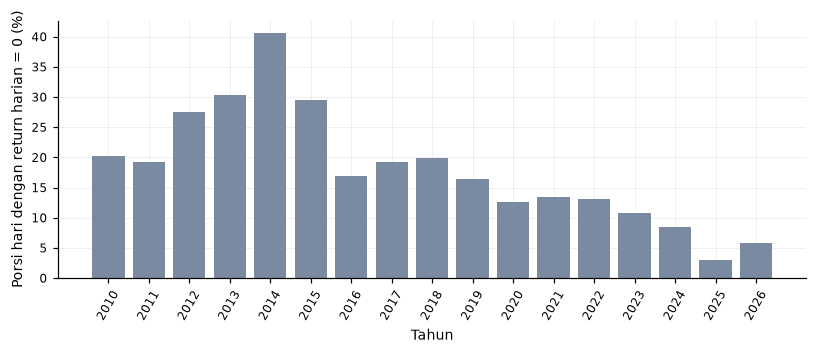

In [18]:
rr = p.pct_change().dropna()
nol_tahun = (rr == 0).groupby(rr.index.year).mean().mul(100).round(1)
tr_d20, va_d20, te_pos20 = multihorizon_split(p, 20)
bagian = {'latih': rr.loc[rr.index.isin(tr_d20)], 'validasi': rr.loc[rr.index.isin(va_d20)], 'uji': rr.loc[rr.index.isin(p.index[te_pos20])]}
nol_bagian = pd.Series({k: round(float((v == 0).mean() * 100), 1) for k, v in bagian.items()}, name='porsi_return_nol_%')
nol_tahun.rename('porsi_return_nol_%').to_csv(os.path.join(RES, 'porsi_return_nol_per_tahun.csv'))
display(nol_bagian.to_frame().T)
fig = P.fig_zero_share(p)
simpan(fig, 'fig_porsi_return_nol')

**Dampak.** Porsi return nol turun dari sekitar seperlima data latih ke sekitar 7% di periode uji. Artinya data latih lebih "kasar/basi" daripada data uji — salah satu alasan model perlu diuji juga pada sub-periode dan walk-forward (notebook 12 dan 16), tidak hanya satu blok uji.